In [1]:
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

# La base du DWH, créée par 04_ETL/etl_pipeline.py
# Le notebook est dans 07_EDA, donc on remonte d'un dossier
con = sqlite3.connect("../04_ETL/project_11_dwh.db")

# Les tables MART disponibles
pd.read_sql_query("SELECT name FROM sqlite_master WHERE name LIKE 'mart_%' ORDER BY name", con)

,name
0,mart_incident_rate_shift_role
1,mart_incidents_by_area
2,mart_incidents_month
3,mart_kpi_summary
4,mart_near_miss
5,mart_recurring_incident_type
6,mart_severity_distribution


In [2]:
kpi = pd.read_sql_query("SELECT * FROM mart_kpi_summary", con)
kpi

,kpi_id,kpi,libelle,valeur,unite
0,KPI1,Incidents/month,Moyenne mensuelle des incidents sur les mois c...,144.00,incidents/mois
1,KPI2,Severity distribution,Part des incidents graves (gravité HIGH ou CRI...,22.30,%
2,KPI3,Incidents by area,Score de risque de la zone la plus à risque : ...,95.40,score /100
3,KPI4,Near-miss count,Presque-accidents : incidents NEAR_MISS + obse...,759.00,near-miss
4,KPI5,Recurring incident type,Part du type d'incident le plus fréquent : SPI...,18.10,%
5,KPI6,Incident rate by shift/role,Incidents par travailleur du groupe le plus to...,4.84,incidents/travailleur
6,KPI7,Unsafe observations,Part des observations de terrain classées UNSAFE,29.40,%
7,KPI8,Total incidents,Nombre d'incidents chargés dans le DWH (contrô...,1400.00,incidents


## Graphique 1 : tendance mensuelle des incidents
*Question HSE : la situation s'améliore-t-elle ou se dégrade-t-elle ?*

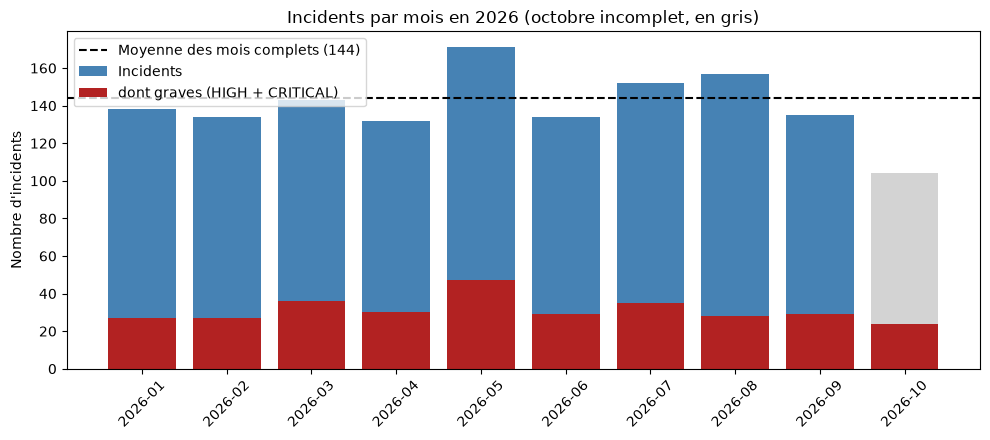

,mois,nb_incidents,nb_graves,pct_graves,mois_complet
0,2026-01,138,27,19.6,1
1,2026-02,134,27,20.1,1
2,2026-03,143,36,25.2,1
3,2026-04,132,30,22.7,1
4,2026-05,171,47,27.5,1
5,2026-06,134,29,21.6,1
6,2026-07,152,35,23.0,1
7,2026-08,157,28,17.8,1
8,2026-09,135,29,21.5,1
9,2026-10,104,24,23.1,0


In [3]:
import os
os.makedirs("figures", exist_ok=True)

mois = pd.read_sql_query("SELECT * FROM mart_incidents_month ORDER BY mois", con)

# Moyenne calculée sur les mois complets seulement (octobre exclu)
moyenne = mois[mois["mois_complet"] == 1]["nb_incidents"].mean()

# Octobre (incomplet) en gris, les autres mois en bleu
couleurs = ["steelblue" if complet == 1 else "lightgray" for complet in mois["mois_complet"]]

plt.figure(figsize=(10, 4.5))
plt.bar(mois["mois"], mois["nb_incidents"], color=couleurs, label="Incidents")
plt.bar(mois["mois"], mois["nb_graves"], color="firebrick", label="dont graves (HIGH + CRITICAL)")
plt.axhline(moyenne, color="black", linestyle="--", label=f"Moyenne des mois complets ({moyenne:.0f})")
plt.title("Incidents par mois en 2026 (octobre incomplet, en gris)")
plt.ylabel("Nombre d'incidents")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("figures/01_tendance_mensuelle.png", dpi=150)
plt.show()

mois[["mois", "nb_incidents", "nb_graves", "pct_graves", "mois_complet"]]

**Interprétation.** Le volume est stable, entre 132 et 157 incidents par mois (moyenne de 144 sur les mois complets), sans tendance nette. **Mai est le pic : 171 incidents**, soit +29,5 % par rapport à avril, avec la plus forte part de graves (27,5 %). Octobre (104) paraît bas, mais il s'arrête au 28 : on ne peut pas conclure à une amélioration.
**Action HSE :** chercher en priorité la cause du pic de mai (activité, saison, effectif).

## Graphique 2 : répartition des incidents par gravité
*Question HSE : quelle part des incidents est vraiment grave ?*

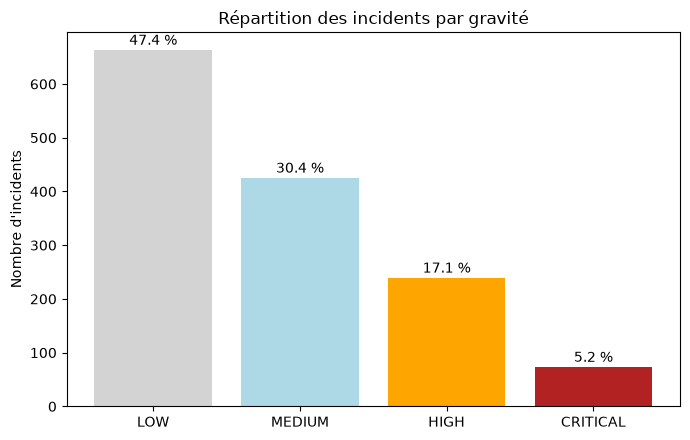

,severity,nb_incidents,pct
0,LOW,663,47.4
1,MEDIUM,425,30.4
2,HIGH,239,17.1
3,CRITICAL,73,5.2


In [4]:
gravite = pd.read_sql_query("SELECT * FROM mart_severity_distribution", con)

# Ordre naturel de la gravité, du plus faible au plus grave
ordre = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
gravite = gravite.set_index("severity").loc[ordre].reset_index()

couleurs = ["lightgray", "lightblue", "orange", "firebrick"]

plt.figure(figsize=(7, 4.5))
plt.bar(gravite["severity"], gravite["nb_incidents"], color=couleurs)

# Écrire le pourcentage au-dessus de chaque barre
for i, ligne in gravite.iterrows():
    plt.text(i, ligne["nb_incidents"] + 10, f"{ligne['pct']} %", ha="center")

plt.title("Répartition des incidents par gravité")
plt.ylabel("Nombre d'incidents")
plt.tight_layout()
plt.savefig("figures/02_gravite.png", dpi=150)
plt.show()

gravite

**Interprétation.** Près de la moitié des incidents sont faibles (LOW : 663, soit 47,4 %). Mais **22,3 % sont graves** : HIGH (239) + CRITICAL (73) = 312 incidents, plus d'un sur cinq. Les 73 incidents critiques représentent environ 7 par mois.
**Action HSE :** fixer un objectif de réduction de la part d'incidents graves, suivi chaque mois.

## Graphique 3 : les zones les plus à risque
*Question HSE : où concentrer les inspections et les rondes de sécurité ?*

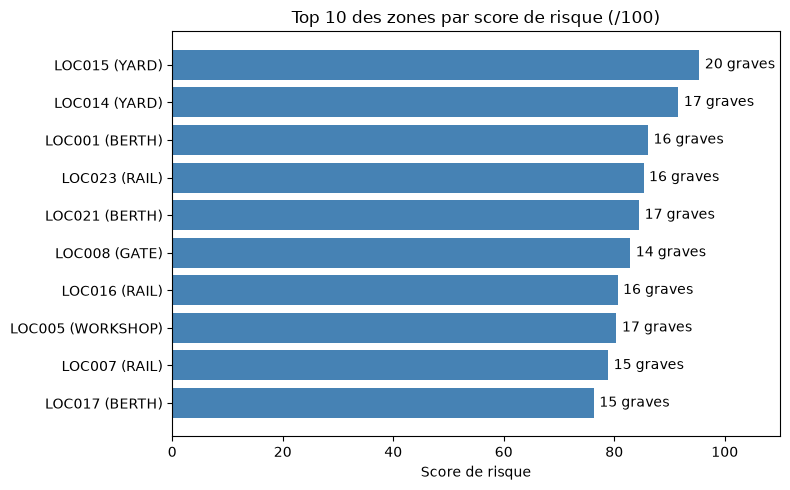

,location_id,area_type,nb_incidents,nb_graves,pct_unsafe,score_risque
0,LOC015,YARD,66,20,28.1,95.4
1,LOC014,YARD,64,17,36.5,91.6
2,LOC001,BERTH,59,16,35.3,86.1
3,LOC023,RAIL,60,16,32.8,85.3
4,LOC021,BERTH,61,17,26.1,84.5
5,LOC008,GATE,64,14,34.3,82.9
6,LOC016,RAIL,55,16,28.5,80.6
7,LOC005,WORKSHOP,56,17,22.8,80.4
8,LOC007,RAIL,55,15,30.0,78.9
9,LOC017,BERTH,54,15,26.1,76.3


In [5]:
zones = pd.read_sql_query(
    "SELECT * FROM mart_incidents_by_area ORDER BY score_risque DESC LIMIT 10", con
)

# Pour barh, la première ligne est dessinée en bas : on inverse pour avoir la plus risquée en haut
zones = zones.sort_values("score_risque")
etiquettes = zones["location_id"] + " (" + zones["area_type"] + ")"

plt.figure(figsize=(8, 5))
plt.barh(etiquettes, zones["score_risque"], color="steelblue")

# Écrire le nombre d'incidents graves à droite de chaque barre
for i, (score, graves) in enumerate(zip(zones["score_risque"], zones["nb_graves"])):
    plt.text(score + 1, i, f"{graves} graves", va="center")

plt.title("Top 10 des zones par score de risque (/100)")
plt.xlabel("Score de risque")
plt.xlim(0, 110)
plt.tight_layout()
plt.savefig("figures/03_zones_risque.png", dpi=150)
plt.show()

zones.sort_values("score_risque", ascending=False)[["location_id", "area_type", "nb_incidents", "nb_graves", "pct_unsafe", "score_risque"]]

**Interprétation.** Le score de risque combine 50 % incidents graves, 30 % nombre d'incidents et 20 % part d'observations UNSAFE. Les deux zones les plus à risque sont des **parcs à conteneurs** : **LOC015 (95,4, 20 graves)** et **LOC014 (91,6, 17 graves)**. Le parc est aussi le type de zone avec la plus forte part d'incidents graves (28 %). Suivent un quai (LOC001), le rail (LOC023) et un autre quai (LOC021).
**Action HSE :** renforcer en priorité les rondes sur le parc à conteneurs, à commencer par LOC015 et LOC014.